# Example: Deep CWFS patch stitching and the four integrators

1. **Stitching.** Deep CWFS runs the network on square patches (`patch_size`, overlapping by `overlap`) and
   averages them back (`blend="mean"`, as in the original script, or `"feather"`, linear ramps over the overlap).
   We compare a single patch covering the whole image with 3×3 patches.

   **The networks expect 500 × 500 px inputs** (their training size; the flow values are not rescaled after the
   network's internal resize). Patches smaller than 500 px are therefore reflect-padded to 500 × 500 before the network
   and the flow is cropped back (`pad_size=500`, default). The last run switches this off to show why it is needed.
2. **Integration.** The displacement is turned into OPD by one of the integrators in `available_integrators()`.
   The default is `poisson_neumann`; any method takes `integrator=...` to switch.

Runs on CUDA if available, else on the CPU (`DEVICE = None`; set `"cpu"` / `"cuda"` to choose). **Use a GPU:** the
network resizes every patch to 540×960, so the forward passes below take seconds on a GPU but over an hour on a
laptop CPU. On the GPU server: see `gpu_server/README.md`, step 5. Data: `$SPECKLE_OPD_DATA` or `../../data`.

In [1]:
import os
import time

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle

from speckle_opd_retrieval import DEFAULT_INTEGRATOR, Setup, available_integrators, get_method, integrate, load_image
from speckle_opd_retrieval.methods.deep_cwfs.patch_tiling_and_stitching import tile_grid

DEVICE = None
DATA = os.environ.get("SPECKLE_OPD_DATA", os.path.join("..", "..", "data"))
SAMPLES = os.path.join(DATA, "2026-04-13_cwfs_speckle_pairs_10_samples")

ref = load_image(os.path.join(SAMPLES, "reference", "0.tiff"))
spec = load_image(os.path.join(SAMPLES, "specimen", "0.tiff"))
setup = Setup(pixel_size=3.45e-6, distance=2.48e-3)
print("image", ref.shape, "| default integrator:", DEFAULT_INTEGRATOR)
available_integrators()

image (500, 500) | default integrator: poisson_neumann


{'poisson_neumann': 'least-squares Poisson solve, Neumann boundaries (DCT): exact and fast (default)',
 'poisson_zero_boundary': 'Poisson solve with OPD = 0 on the border (conjugate gradients): original Deep CWFS solver',
 'fourier_mirror': 'Fourier integration, gradients mirror-padded by N/2 (signs kept): loses tilts',
 'fourier_asdi': 'Fourier integration, anti-symmetric derivative extension (ASDI): no boundary artefacts'}

In [2]:
def show(ax, img, title, cmap="gray", symmetric=False, label="", vmin=None, vmax=None):
    """imshow with a colour bar; ``symmetric`` centres a diverging colour map on 0."""
    if symmetric:
        vmax = np.abs(img).max()
        vmin = -vmax
    im = ax.imshow(img, cmap=cmap, vmin=vmin, vmax=vmax)
    plt.colorbar(im, ax=ax, shrink=0.8, label=label)
    ax.set_title(title, fontsize=10)
    ax.axis("off")


def draw_tiles(ax, corners, patch, colour="tab:orange"):
    """Outline each patch (top-left ``corners``, size ``patch``) on an image axis."""
    for row, col in corners:
        ax.add_patch(Rectangle((col - 0.5, row - 0.5), patch, patch, fill=False, edgecolor=colour, lw=0.8))

## 1. Stitching

Four runs of the default model (longer-trained SEA-RAFT medium): one 500 px patch (no stitching); 256 px patches with
64 px overlap, each padded to 500 × 500, blended by `mean` and by `feather`; and the same without padding
(`pad_size=None`). The model is loaded once per retriever.

In [3]:
PATCH, OVERLAP = 256, 64
corners = tile_grid(ref.shape, PATCH, OVERLAP)
print(f"{len(corners)} patches at", corners)

runs = {
    "one patch (500 px)": dict(patch_size=500),
    "3×3 patches, mean": dict(patch_size=PATCH, overlap=OVERLAP, blend="mean"),
    "3×3 patches, feather": dict(patch_size=PATCH, overlap=OVERLAP, blend="feather"),
    "3×3 patches, no padding": dict(patch_size=PATCH, overlap=OVERLAP, blend="feather", pad_size=None),
}
deep = {}
for name, settings in runs.items():
    result = get_method("deep_cwfs", setup, device=DEVICE, **settings).retrieve(ref, spec)
    deep[name] = result
    print(f"{name:22s} {result.info['runtime_s']:.1f} s on {result.params['device']}")

9 patches at [(0, 0), (0, 192), (0, 244), (192, 0), (192, 192), (192, 244), (244, 0), (244, 192), (244, 244)]


/home/kazim/anaconda3/envs/speckle_qpi/lib/python3.10/site-packages/torch/functional.py:534: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /home/conda/feedstock_root/build_artifacts/libtorch_1737846239921/work/aten/src/ATen/native/TensorShape.cpp:3595.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


one patch (500 px)     0.4 s on cuda


3×3 patches, mean      1.2 s on cuda


deep_cwfs: patch_size 256 without padding; the networks expect 500 px inputs


3×3 patches, feather   1.2 s on cuda


3×3 patches, no padding 1.2 s on cuda


3×3 patches, mean      RMS difference to one patch 0.0140 px (RMS displacement 0.1623 px)
3×3 patches, feather   RMS difference to one patch 0.0072 px (RMS displacement 0.1623 px)
3×3 patches, no padding RMS difference to one patch 0.1160 px (RMS displacement 0.1623 px)


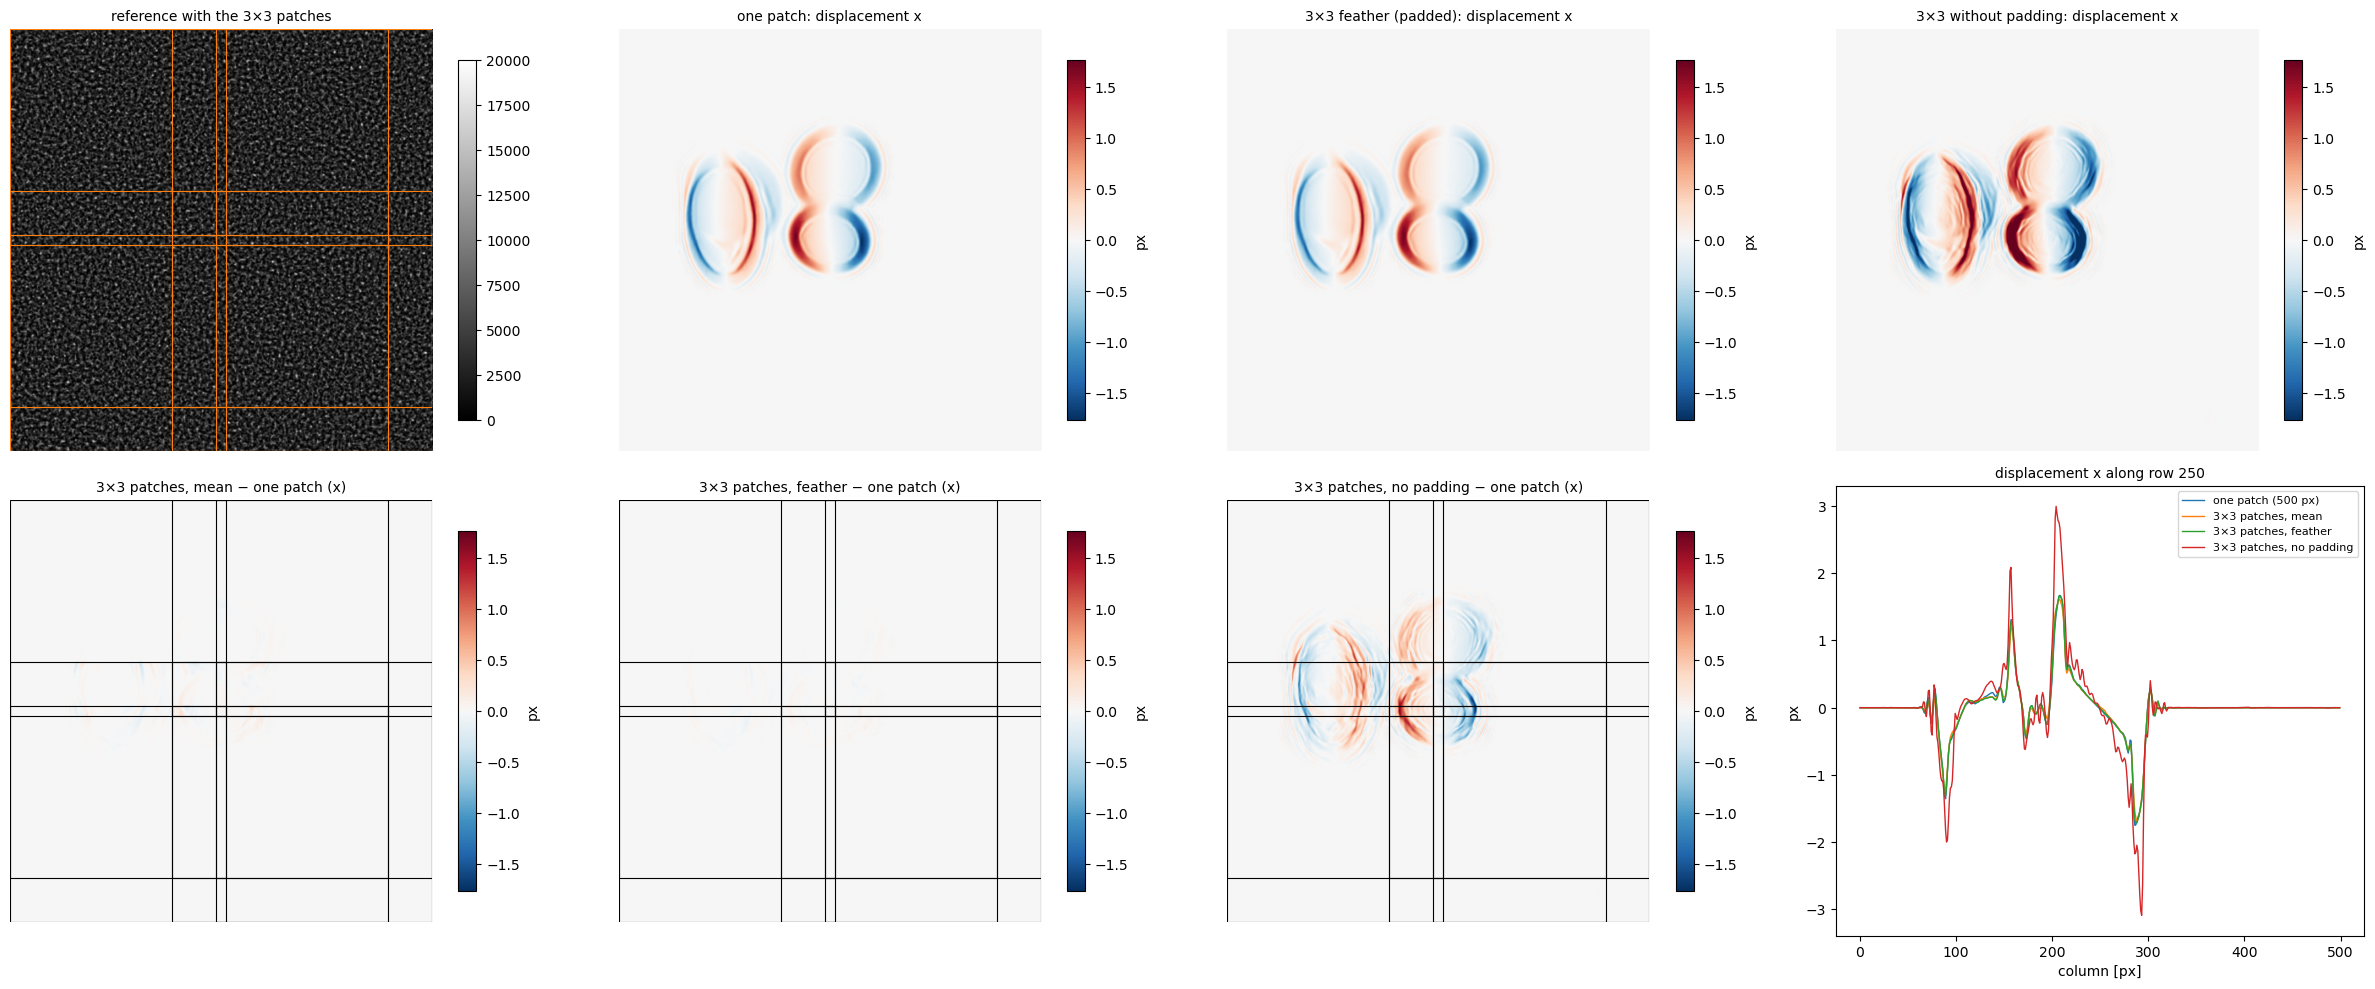

In [4]:
single = deep["one patch (500 px)"].displacement
limit = np.abs(single[1]).max()
fig, axs = plt.subplots(2, 4, figsize=(24, 10))
show(axs[0, 0], ref, "reference with the 3×3 patches")
draw_tiles(axs[0, 0], corners, PATCH)
show(axs[0, 1], single[1], "one patch: displacement x", "RdBu_r", vmin=-limit, vmax=limit, label="px")
show(axs[0, 2], deep["3×3 patches, feather"].displacement[1], "3×3 feather (padded): displacement x", "RdBu_r",
     vmin=-limit, vmax=limit, label="px")
show(axs[0, 3], deep["3×3 patches, no padding"].displacement[1], "3×3 without padding: displacement x", "RdBu_r",
     vmin=-limit, vmax=limit, label="px")
for ax, name in zip(axs[1], ["3×3 patches, mean", "3×3 patches, feather", "3×3 patches, no padding"]):
    show(ax, deep[name].displacement[1] - single[1], f"{name} − one patch (x)", "RdBu_r", vmin=-limit, vmax=limit,
         label="px")
    draw_tiles(ax, corners, PATCH, "k")
row = ref.shape[0] // 2
for name, result in deep.items():
    axs[1, 3].plot(result.displacement[1, row], label=name, lw=1)
axs[1, 3].set_title(f"displacement x along row {row}", fontsize=10)
axs[1, 3].set_xlabel("column [px]")
axs[1, 3].set_ylabel("px")
axs[1, 3].legend(fontsize=8)
plt.tight_layout()

for name in ["3×3 patches, mean", "3×3 patches, feather", "3×3 patches, no padding"]:
    difference = deep[name].displacement - single
    print(f"{name:22s} RMS difference to one patch {np.sqrt(np.mean(difference ** 2)):.4f} px "
          f"(RMS displacement {np.sqrt(np.mean(single ** 2)):.4f} px)")

**What to look for.**
- *Without padding*, the 256 px patches are magnified about twice as much by the network's resize as the 500 px
  training inputs, and the displacement comes out about 1.8× too large (first GPU run, 28 Oct 2026). This is a scale
  error, not a seam.
- *With padding* (default), every patch reaches the network as 500 × 500 px, so the magnitudes should match the
  single patch; what remains are differences between patches in their overlaps.
- `mean` averages overlapping patches with equal weights and can leave steps at patch edges; `feather` lowers the
  weight towards each patch edge, which hides them.

## 2. The four integrators on the same displacement

The displacement of the padded `feather` run is integrated with every integrator via `integrate(displacement, name)`;
the same is obtained by creating the method with `integrator=name` (shown in the last cell).

In [5]:
displacement = deep["3×3 patches, feather"].displacement
opd = {}
for name in available_integrators():
    t0 = time.perf_counter()
    opd[name] = setup.opd_scale * integrate(displacement, name, device=DEVICE) * 1e6   # µm
    print(f"{name:22s} {time.perf_counter() - t0:6.2f} s, OPD range {np.ptp(opd[name]):.3f} µm, "
          f"RMS difference to {DEFAULT_INTEGRATOR}: {np.sqrt(np.mean((opd[name] - opd[DEFAULT_INTEGRATOR]) ** 2)) * 1e3:.2f} nm")

poisson_neumann          0.03 s, OPD range 0.210 µm, RMS difference to poisson_neumann: 0.00 nm


poisson_zero_boundary    4.02 s, OPD range 0.211 µm, RMS difference to poisson_neumann: 1.11 nm
fourier_mirror           0.02 s, OPD range 0.212 µm, RMS difference to poisson_neumann: 1.54 nm
fourier_asdi             0.02 s, OPD range 0.210 µm, RMS difference to poisson_neumann: 0.45 nm


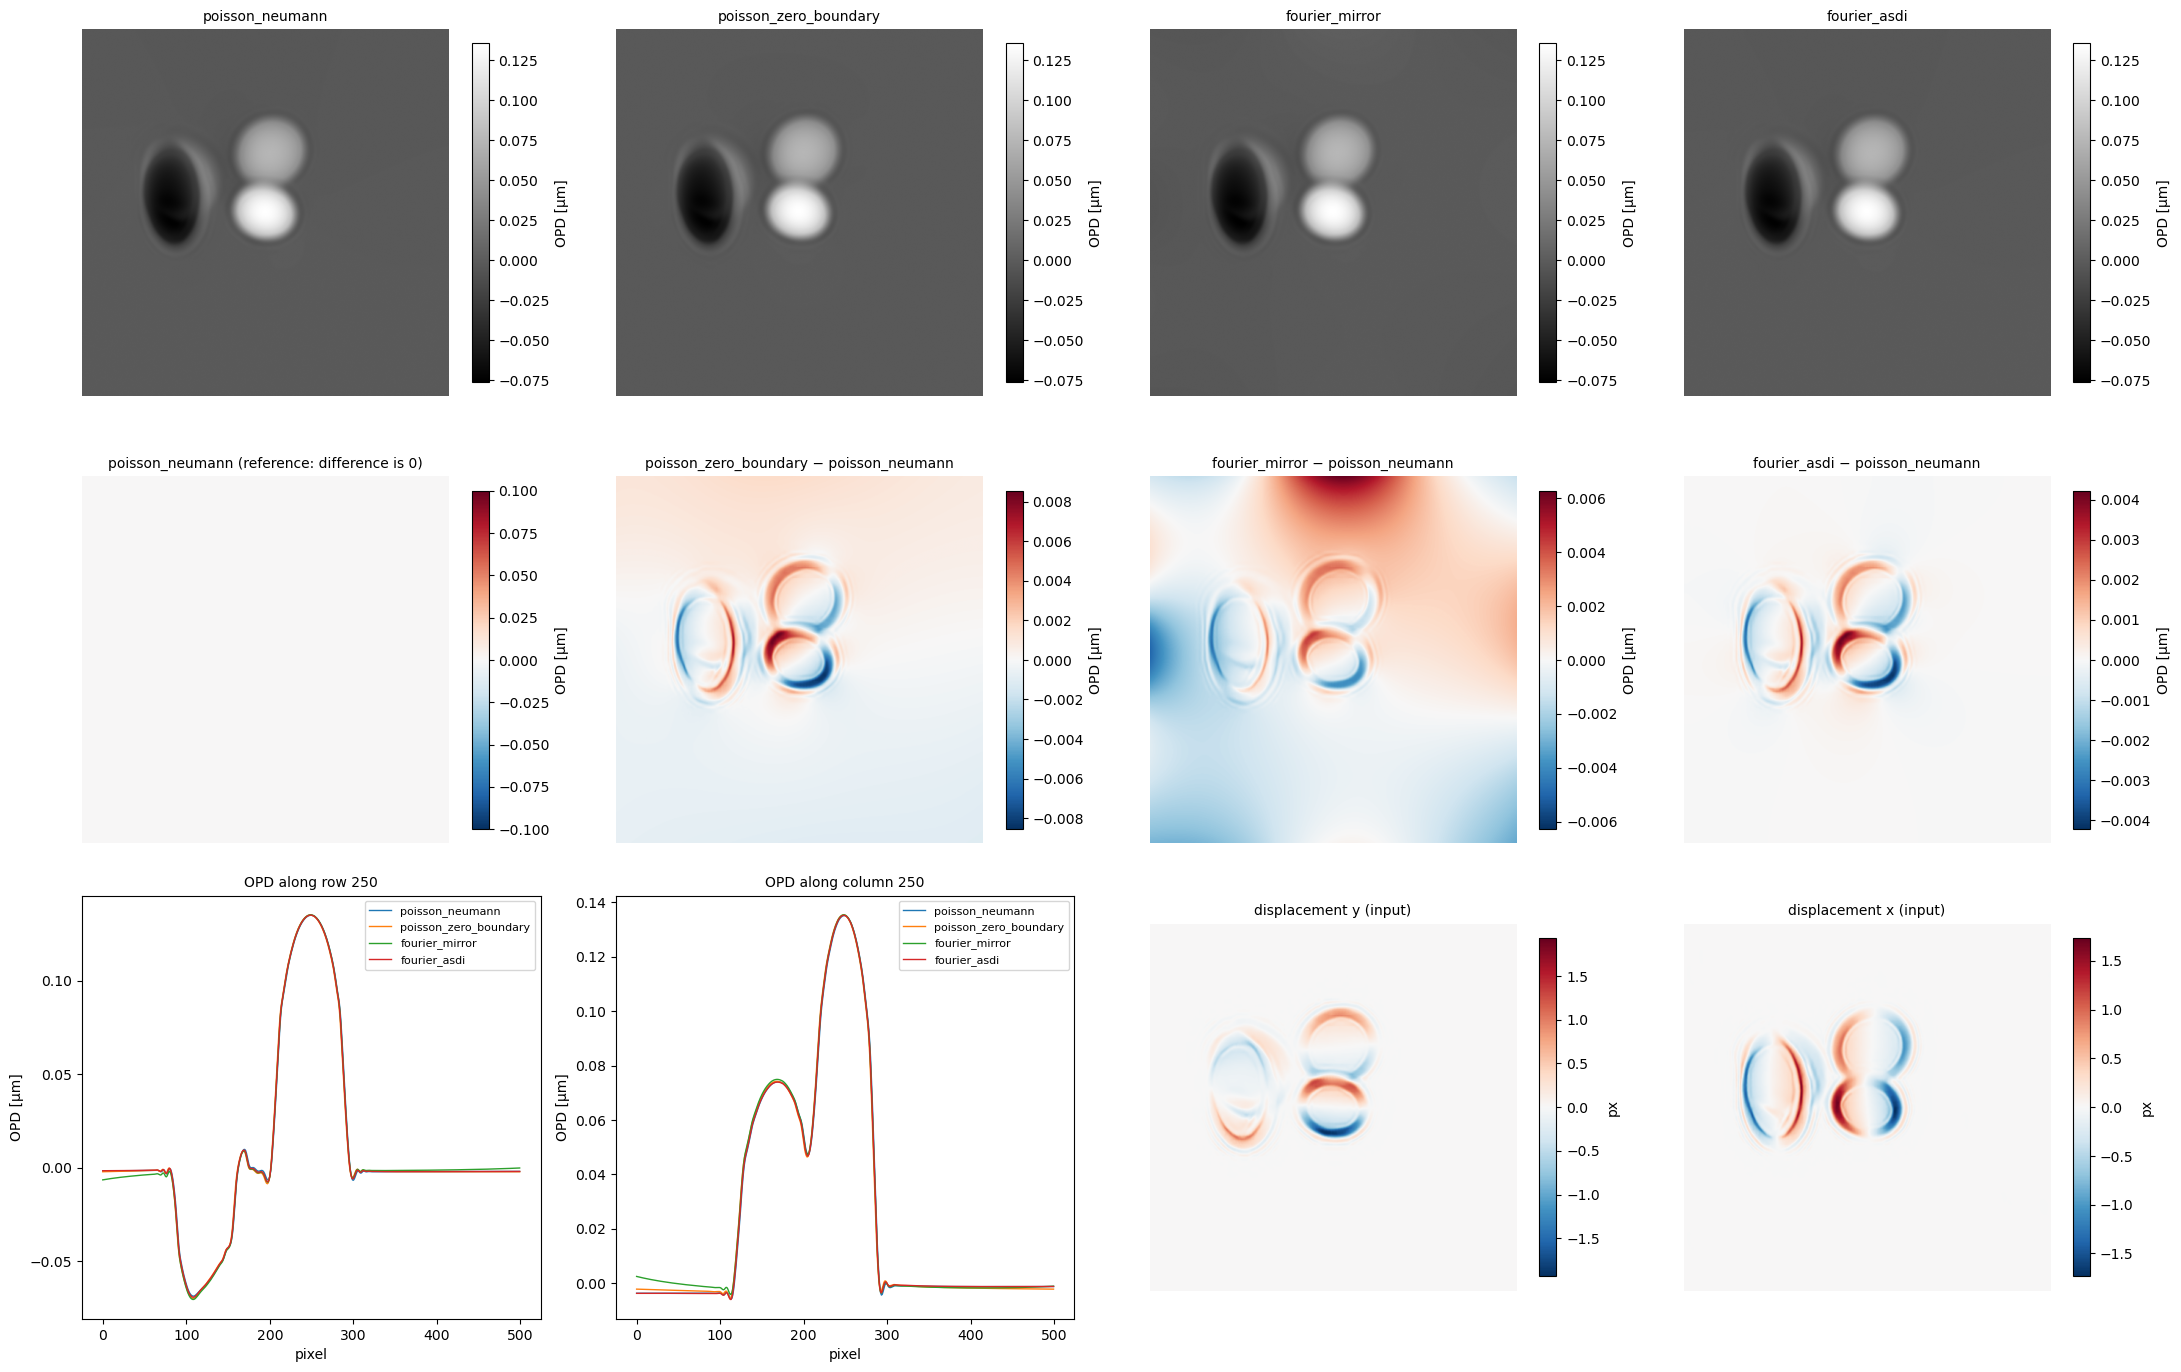

In [6]:
names = list(opd)
lo = min(o.min() for o in opd.values())
hi = max(o.max() for o in opd.values())
fig, axs = plt.subplots(3, 4, figsize=(22, 14))
for col, name in enumerate(names):
    show(axs[0, col], opd[name], name, label="OPD [µm]", vmin=lo, vmax=hi)
    show(axs[1, col], opd[name] - opd[DEFAULT_INTEGRATOR], f"{name} − {DEFAULT_INTEGRATOR}", "RdBu_r",
         symmetric=True, label="OPD [µm]")
row = ref.shape[0] // 2
column = ref.shape[1] // 2
for name in names:
    axs[2, 0].plot(opd[name][row], label=name, lw=1)
    axs[2, 1].plot(opd[name][:, column], label=name, lw=1)
axs[2, 0].set_title(f"OPD along row {row}", fontsize=10)
axs[2, 1].set_title(f"OPD along column {column}", fontsize=10)
for ax in axs[2, :2]:
    ax.set_xlabel("pixel")
    ax.set_ylabel("OPD [µm]")
    ax.legend(fontsize=8)
show(axs[2, 2], displacement[0], "displacement y (input)", "RdBu_r", symmetric=True, label="px")
show(axs[2, 3], displacement[1], "displacement x (input)", "RdBu_r", symmetric=True, label="px")
axs[1, 0].set_title(f"{DEFAULT_INTEGRATOR} (reference: difference is 0)", fontsize=10)
plt.tight_layout()

What to expect (see `notebooks/integration_boundary_conditions_explained.ipynb` for synthetic cases with known truth):
- `poisson_neumann` (default) and `fourier_asdi` agree closely: both keep tilts and make no assumption about the
  border values.
- `poisson_zero_boundary` (the original Deep CWFS solver) forces the OPD to 0 on the border; on this pair the object
  sits in the middle, so the difference is small.
- `fourier_mirror` keeps the gradient signs when padding, so any tilt (mean gradient) is removed.

## 3. Switching the integrator on a method

In [7]:
dic_default = get_method("dic", setup, saturation=float(ref.max()), device=DEVICE)
dic_asdi = get_method("dic", setup, saturation=float(ref.max()), device=DEVICE, integrator="fourier_asdi")
print(dic_default)
print(dic_asdi)
a = dic_default.retrieve(ref, spec)
b = dic_asdi.retrieve(ref, spec)
print(f"DIC, {a.params['integrator']} vs {b.params['integrator']}: RMS difference "
      f"{np.sqrt(np.mean((a.opd - b.opd) ** 2)) * 1e9:.2f} nm, OPD range {np.ptp(a.opd) * 1e6:.3f} µm")

DIC(window=32, step=8, search=7, sigma=6.0, saturation=20000.0, integrator='poisson_neumann', device='cuda')
DIC(window=32, step=8, search=7, sigma=6.0, saturation=20000.0, integrator='fourier_asdi', device='cuda')


DIC, poisson_neumann vs fourier_asdi: RMS difference 0.24 nm, OPD range 0.155 µm
